# 09 – Axis, core and halo (particle issue #1, Q1 and Q2)

**Definitions** (issue #1). The **axis** is the straight line of the incoming direction (θ, φ) from the vertex (0, 0, 0); it enters
the calorimeter at the front face z = 3620.0 mm (ePIC `LFHCAL_zmin`). In front of the first tile there are 40.4 mm of steel (25.4 mm
mounting plate + 15 mm module front wall); every layer is 4 mm scintillator, 0.8 mm Kapton and 15.2 mm steel, so **a tile sits in front of
its absorber** and an interaction in the steel behind tile k is first seen in tile k + 1. Depths are measured from the entry point along the
axis. Every event is split into three regions: the **MIP segment** (energy within R = 5 cm of the axis in the tiles before the shower
start), the **core** (within 5 cm, from the shower start on) and the **halo** (farther than 5 cm): `E_vis = E_MIP + E_core + E_halo`.
A cell's energy is shared by the part of its 48.6 × 48.6 mm face inside R (8 × 8 points, "folding"); the cell-centre rule is kept for
comparison. Only prompt deposits (t < 100 ns) count, as in the report.

**Selection and statistics.** The entry point must be in the instrumented area and the axis must stay 10 cm inside it in all 60 layers
(no lateral leakage at the outer edge or the beam hole; 59 % of the events). Ratios of sums carry bootstrap errors, AUCs Hanley–McNeil
errors; efficiencies at 99 % electron rejection use thresholds from the train + val electrons applied to the test split.

**Simulation truth** (validation only). The CSV gives each cell's earliest contributor with its complete list of direct daughters. The
primary's cells are its prompt passage along the axis (99.9 % within 33 mm and within 0.06 ns of straight-line flight), so the deepest
primary tile marks the end of its track; daughters with hadronic products (n, π, d, α, ...) mark an inelastic interaction, no primary cell
at all an interaction in the front steel. About 13 % of crossed tiles miss the primary's cell (gaps, δ electrons arriving first).

In [1]:
import os, sys, json
_d = os.getcwd()                                              # find the repository root, so that the notebook runs from any folder
while not os.path.exists(os.path.join(_d, "ALL-README.md")) and os.path.dirname(_d) != _d:
    _d = os.path.dirname(_d)
os.chdir(_d)
sys.path.insert(0, os.path.abspath("src"))
import numpy as np, pandas as pd
from IPython.display import display
import core_mip as cm, core_mip_analysis as A, core_mip_figures as G
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
F = A.load_all()                                              # fiducial events with E_vis > 0
FINDER = json.load(open(os.path.join(cm.FEAT, "mip_finder.json")))
HAVE_CACHE = all(os.path.exists(os.path.join(cm.CACHE_DIR, f"{p}_s1.npz")) for p in A.PARTICLES)
NO_CACHE = ("needs the per-layer cache, which is not in git: python src/core_mip.py build <particle> (muon first; "
            "reads the simulation CSVs from $LFHCAL_DATA)")
print({p: len(f) for p, f in F.items()}, "events;  finder:", FINDER["versions"]["strict"], ";  per-layer cache:", HAVE_CACHE)

{'electron': 59475, 'muon': 59414, 'pion': 59333, 'proton': 59257} events;  finder: {'core_up': 2.0, 'halo_up': inf, 'cells_up': 2, 'n_consec': 2, 'core_sum': 6.0, 'core_sum_per_gev': 0.5} ;  per-layer cache: True


## Q1 – How is the visible energy split between MIP segment, core and halo?

Shares of `E_vis` (ratio of sums over the events of each 1 GeV/c bin, and the event mean; the MIP segment is found as described in notebook 10).

event_mean               ratio_of_sums              
component           MIP   core   halo           MIP   core   halo
particle bin                                                     
electron 0        0.303  0.499  0.199         0.165  0.698  0.137
         1        0.014  0.875  0.112         0.009  0.881  0.110
         2        0.002  0.890  0.107         0.002  0.892  0.106
         4        0.001  0.894  0.105         0.001  0.896  0.104
         9        0.000  0.896  0.104         0.000  0.897  0.102
         14       0.000  0.897  0.103         0.000  0.898  0.102
         19       0.000  0.897  0.103         0.000  0.898  0.102
muon     0        0.736  0.018  0.247         0.709  0.015  0.276
         1        0.637  0.037  0.326         0.634  0.041  0.325
         2        0.736  0.077  0.187         0.728  0.085  0.187
         4        0.801  0.122  0.077         0.780  0.142  0.078
         9        0.855  0.108  0.038         0.814  0.146  0.040
         14       0.878  0.090  0.032         0.828  0.138  0.034
         19       0.907  0.062  0.031         0.853  0.113  0.034
pion     0        0.427  0.114  0.460         0.409  0.146  0.445
         1        0.254  0.210  0.536         0.237  0.226  0.536
         2        0.154  0.273  0.572         0.145  0.283  0.572
         4        0.085  0.345  0.570         0.076  0.353  0.571
         9        0.048  0.440  0.512         0.035  0.451  0.514
         14       0.031  0.468  0.501         0.023  0.476  0.502
         19       0.028  0.490  0.482         0.018  0.499  0.483
proton   0        0.413  0.385  0.202         0.399  0.498  0.102
         1        0.435  0.181  0.385         0.422  0.204  0.375
         2        0.232  0.217  0.551         0.222  0.231  0.546
         4        0.097  0.290  0.613         0.093  0.296  0.611
         9        0.041  0.379  0.581         0.036  0.383  0.581
         14       0.025  0.408  0.567         0.022  0.412  0.567
         19       0.020  0.424  0.556         0.017  0.428  0.556

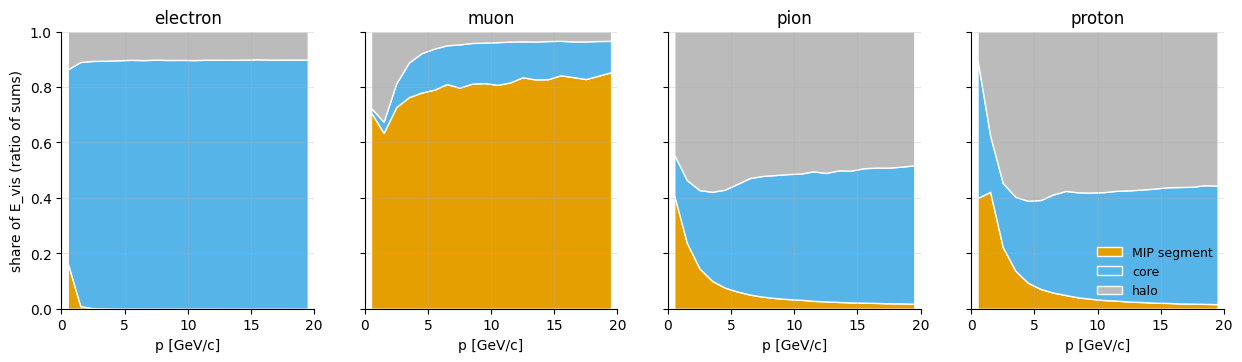

In [2]:
Q1 = A.q1_fractions(F)
G.q1_fractions(Q1)
t = Q1[Q1.version == "strict"].pivot_table(index=["particle", "bin"], columns="component", values=["ratio_of_sums", "event_mean"])
display(t.loc[(slice(None), [0, 1, 2, 4, 9, 14, 19]), :].round(3))

### Where the energy goes

Mean energy density per event against the depth along the axis and the distance from it, 4.5–5.5 GeV/c (cell centres; computed from the CSVs by `scripts/core_mip_region_map.py`). Dashed: R = 5 cm; orange: the median shower start of pions and protons. Inside 5 cm before the mark lies the MIP segment, after it the core, outside the halo.

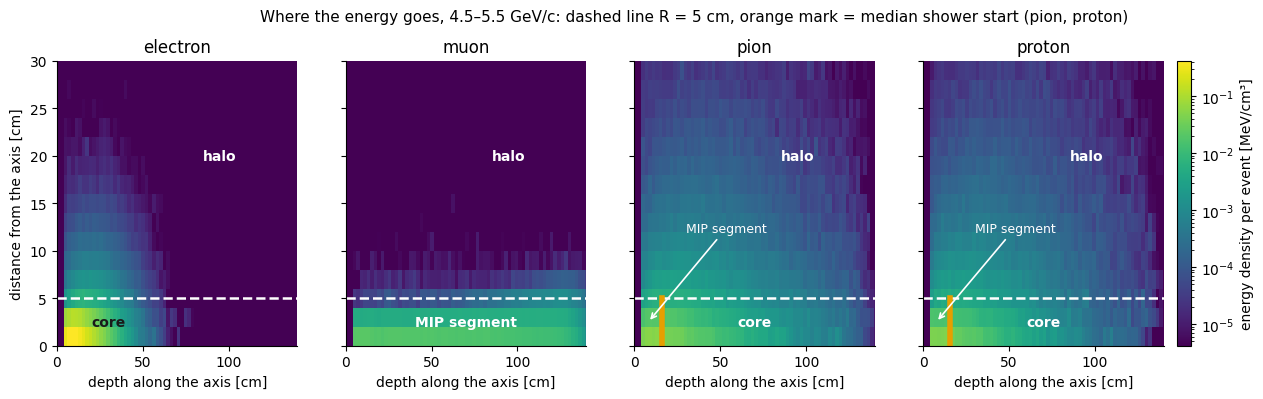

In [3]:
_ = G.q1_region_map() if os.path.exists("results/core_mip/q1_region_map.npz") else print("run scripts/core_mip_region_map.py first")

### Why R = 5 cm

The energy within R of the axis (folding), and the separation of electrons from hadrons by that energy (AUC averaged over 2–20 GeV/c). One cell is 48.6 mm wide: below about 5 cm the folding assumption (uniform energy in a cell) dominates, so R = 2.5 cm is a statement about the granularity rather than about the shower.

,R25,R50,R75,R100,centre_R50
electron,0.450,0.898,0.965,0.982,0.931
muon,0.478,0.933,0.981,0.991,0.961
pion,0.205,0.495,0.649,0.742,0.527
proton,0.173,0.433,0.588,0.689,0.460


muon: share of the energy within 10 cm that lies within R: {'R25': 0.482, 'R50': 0.941, 'R75': 0.99}


R_mm,25,50,75,100
pair,,,,
electron_vs_pion,0.9727,0.9865,0.9841,0.9822
electron_vs_proton,0.9913,0.9978,0.9978,0.9974


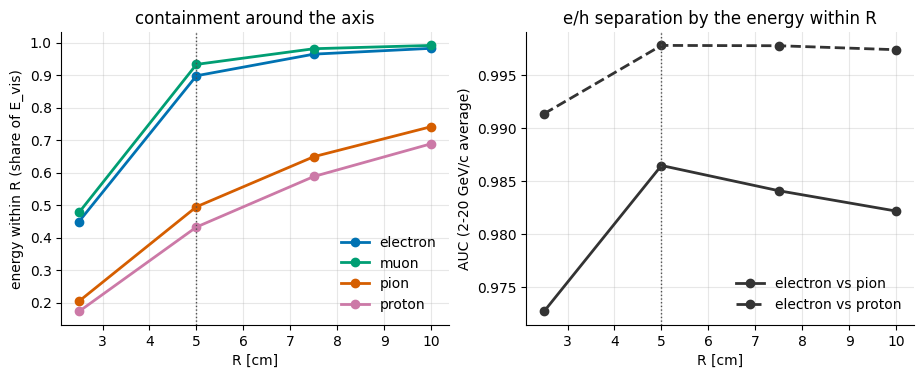

In [4]:
CONT, RS = A.q1_rscan(F)
G.q1_rscan(CONT, RS)
display(pd.DataFrame({p: {k: v for k, v in c.items() if k != "rel_to_R100"} for p, c in CONT.items()}).T.round(3))
print("muon: share of the energy within 10 cm that lies within R:", {k: round(v, 3) for k, v in CONT["muon"]["rel_to_R100"].items()})
sep = RS[(RS.bin >= 2) & (RS.R_mm != "centre50")].assign(sep=lambda d: 1 - d.auc).pivot_table(index="pair", columns="R_mm", values="sep")
display(sep.loc[["electron_vs_pion", "electron_vs_proton"]].round(4))

## Q2 – Is the core fraction of protons ~60 % at 1 GeV/c and ~43 % for pions?

The infographic numbers are the share of the *axial term* of the fitted shape formula (a model component for the primary's passage), not a measurement. The table compares them with the measured `f_core`, with the whole axis region `f_core + f_MIP`, and with the simulation truth: the primary's own share of `E_vis`, the part of `f_core` that the primary itself deposited after the MIP segment (its passage, e.g. the Bragg region of a stopping proton), and how the primary track ended.

,particle,p_window,events,f_core,f_core_se,f_core_event_mean,f_core_half_window,f_MIP,f_core_plus_MIP,formula_axial_term,truth_primary_share,truth_core_from_primary_passage,f_core_interacting,f_core_not_interacting,truth_before_layer1,truth_inelastic,truth_stops,truth_reaches_tile2
0,electron,0.9-1.1,632,0.848,0.006,0.833,0.846,0.038,0.885,0.000,0.049,0.044,0.845,0.852,0.589,0.000,0.411,0.255
1,electron,4.75-5.25,1522,0.897,0.001,0.895,0.898,0.000,0.897,0.000,0.013,0.012,0.896,0.898,0.685,0.000,0.315,0.229
2,electron,19.5-20.0,1431,0.898,0.001,0.896,0.897,0.000,0.898,0.000,0.005,0.004,0.898,0.897,0.781,0.000,0.219,0.168
3,muon,0.9-1.1,615,0.020,0.004,0.018,0.017,0.648,0.668,0.909,0.929,0.017,0.018,0.022,0.000,0.512,0.488,1.000
4,muon,4.75-5.25,1535,0.148,0.007,0.122,0.156,0.783,0.931,0.880,0.815,0.096,NaN,0.146,0.001,0.003,0.138,0.999
5,muon,19.5-20.0,1496,0.112,0.009,0.062,0.103,0.854,0.966,0.925,0.742,0.037,NaN,0.112,0.001,0.003,0.149,0.999
6,pion,0.9-1.1,686,0.191,0.010,0.182,0.190,0.317,0.508,0.430,0.254,0.033,0.195,NaN,0.292,0.692,0.000,0.630
7,pion,4.75-5.25,1486,0.372,0.005,0.362,0.371,0.069,0.440,0.267,0.063,0.019,0.372,NaN,0.220,0.777,0.000,0.714
8,pion,19.5-20.0,1448,0.500,0.004,0.491,0.502,0.017,0.517,0.289,0.016,0.004,0.500,NaN,0.218,0.776,0.000,0.712
9,proton,0.9-1.1,1133,0.396,0.010,0.327,0.374,0.472,0.869,0.605,0.675,0.260,0.347,0.448,0.250,0.353,0.397,0.678


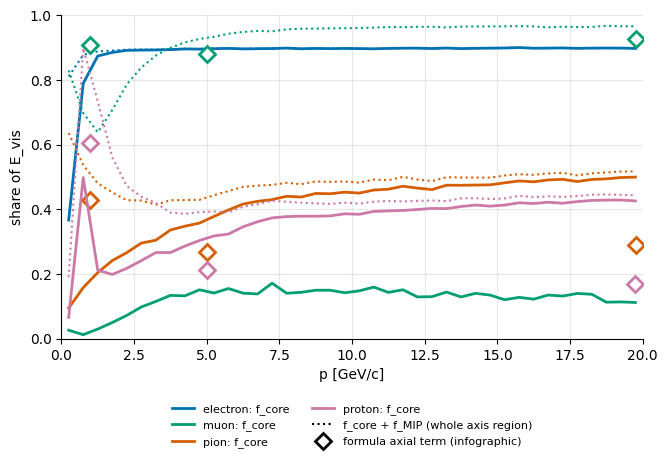

In [5]:
Q2 = A.q2_table(F)
cols = ["particle", "p_window", "events", "f_core", "f_core_se", "f_core_event_mean", "f_core_half_window", "f_MIP", "f_core_plus_MIP",
        "formula_axial_term", "truth_primary_share", "truth_core_from_primary_passage", "f_core_interacting", "f_core_not_interacting",
        "truth_before_layer1", "truth_inelastic", "truth_stops", "truth_reaches_tile2"]
display(Q2[cols].round(3))
_ = G.q2_fcore(F, Q2)

### `f_core` as a feature

AUC per momentum bin on the test split (0.5 = no separation). For π vs. p the orientation is fixed (probability that a proton has the larger `f_core`), so a change of sign is visible. The ratio core / rest of the shower is a monotonic function of `f_core` and has the same AUC.

,pion vs proton,electron vs pion,electron vs proton
bin,,,
0,0.656,0.742,0.591
1,0.451,0.985,0.977
2,0.407,1.000,0.997
4,0.411,0.998,1.000
9,0.393,0.999,1.000
14,0.362,0.998,1.000
19,0.347,0.996,1.000


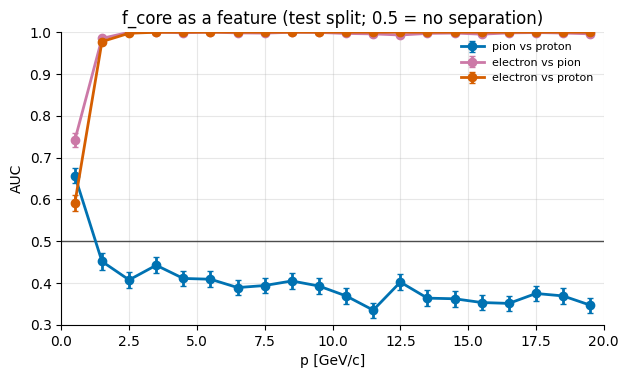

In [6]:
AUC = {"pion vs proton": A.auc_by_bin(F, "pion", "proton", "f_core_strict", split="test"),
       "electron vs pion": A.auc_by_bin(F, "electron", "pion", "f_core_strict", sign=-1.0, split="test"),
       "electron vs proton": A.auc_by_bin(F, "electron", "proton", "f_core_strict", sign=-1.0, split="test")}
G.q2_auc(AUC)
display(pd.DataFrame({k: d.set_index("bin").auc for k, d in AUC.items()}).loc[[0, 1, 2, 4, 9, 14, 19]].round(3))